# Contoh dashboard harga Mangga Manalagi

Prototipe **sekali pakai** (matplotlib + seaborn) sebelum dibuat di website. Tujuannya melihat
apakah keempat grafik ini menjawab pertanyaan Ibuk, bukan tampilan akhir.

| # | Grafik | Pertanyaan yang dijawab |
|---|---|---|
| 1 | Angka utama: median, rata-rata, rata-rata tertimbang terjual | Berapa harga Manalagi sekarang? |
| 2 | Histogram harga per kg + harga Ibuk | Harga Ibuk murah atau mahal dibanding pasar? |
| 3 | Tren harian, produk yang sama | Harga naik atau turun? |
| 5 | Blibli vs Tokopedia, per wilayah | Di mana lebih murah? (butuh ±1 bulan data) |

Data: `v_produk`, Mangga Manalagi segar (`NOT olahan`), opsi bawaan (`opsi_default`),
harga per kg diketahui, mulai 8 Nov (tanggal pertama kedua marketplace lengkap).

In [ ]:
import duckdb
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import seaborn as sns

HARGA_IBUK = 30_000      # CONTOH: ganti dengan harga jual Ibuk per kg

# Warna (palet dataviz, mode terang): seri 1 biru, seri 2 oranye; teks pakai tinta, bukan warna seri.
BIRU, ORANYE = "#2a78d6", "#eb6834"
TINTA, TINTA_2, REDUP = "#0b0b0b", "#52514e", "#898781"
GRID, SUMBU, PERMUKAAN = "#e1e0d9", "#c3c2b7", "#fcfcfb"

sns.set_theme(style="whitegrid", font="Segoe UI", rc={
    "figure.facecolor": PERMUKAAN, "axes.facecolor": PERMUKAAN,
    "axes.edgecolor": SUMBU, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.labelcolor": TINTA_2, "xtick.color": REDUP, "ytick.color": REDUP,
    "text.color": TINTA, "axes.titleweight": "bold", "axes.titlesize": 13,
    "axes.titlelocation": "left", "lines.linewidth": 2,
})

def rupiah(x, _=None):
    return "Rp" + f"{x:,.0f}".replace(",", ".")

RUPIAH = mtick.FuncFormatter(rupiah)

In [ ]:
SQL = '''
SELECT tanggal, sumber, produk_key, nama, nama_toko, kota, region,
       harga, berat_gram, harga_per_kg, terjual_min
FROM v_produk
WHERE jenis_buah = 'mangga' AND nama ILIKE '%manalagi%'
  AND opsi_default AND NOT olahan AND harga_per_kg IS NOT NULL
  AND tanggal >= DATE '2026-11-08'
'''
# read_only + langsung ditutup: muat terjadwal 06:00/12:00 butuh gudang tidak sedang dibuka.
with duckdb.connect("warehouse/harga_buah.duckdb", read_only=True) as con:
    df = con.sql(SQL).df()

df["tanggal"] = pd.to_datetime(df["tanggal"])
terakhir = df["tanggal"].max()
hari_ini = df[df["tanggal"] == terakhir]
print(f"{len(df)} baris, {df['produk_key'].nunique()} produk, "
      f"{df['tanggal'].nunique()} hari ({df['tanggal'].min():%d %b} – {terakhir:%d %b})")
print(f"Hari terakhir {terakhir:%d %b %Y}: {len(hari_ini)} produk")

157 baris, 39 produk, 6 hari (08 Nov – 13 Nov)
Hari terakhir 13 Nov 2026: 29 produk


## 1. Angka utama hari ini

Satu angka tidak butuh grafik, jadi bentuknya **kotak angka**.
- **Median**: harga tengah, tidak terseret toko yang sangat mahal/murah. Angka utama.
- **Rata-rata**: yang diminta pemilik; ditampilkan supaya bisa dibandingkan.
- **Tertimbang terjual**: rata-rata yang diberi bobot `terjual_min`, mendekati harga yang
  benar-benar dibayar pembeli. `terjual_min` adalah jumlah terjual seumur toko ("1rb+"),
  batas bawah, bukan penjualan minggu ini, jadi angka ini perkiraan kasar.

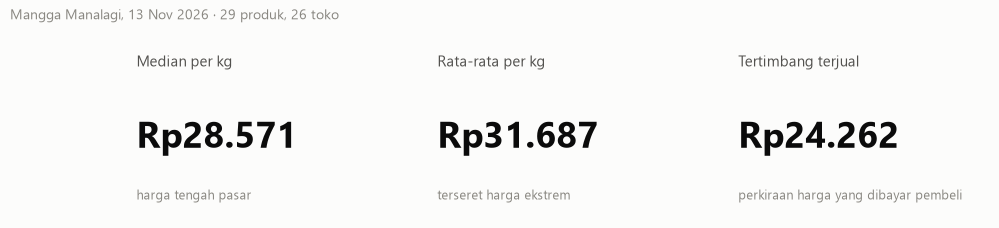

In [ ]:
ada_terjual = hari_ini.dropna(subset=["terjual_min"])
angka = [
    ("Median per kg", hari_ini["harga_per_kg"].median(), "harga tengah pasar"),
    ("Rata-rata per kg", hari_ini["harga_per_kg"].mean(), "terseret harga ekstrem"),
    ("Tertimbang terjual", np.average(ada_terjual["harga_per_kg"], weights=ada_terjual["terjual_min"]),
     "perkiraan harga yang dibayar pembeli"),
]

fig, axes = plt.subplots(1, 3, figsize=(11, 2.4))
for ax, (judul, nilai, catatan) in zip(axes, angka):
    ax.axis("off")
    ax.text(0, 0.82, judul, fontsize=11, color=TINTA_2, transform=ax.transAxes)
    ax.text(0, 0.38, rupiah(nilai), fontsize=26, weight="bold", color=TINTA, transform=ax.transAxes)
    ax.text(0, 0.10, catatan, fontsize=9.5, color=REDUP, transform=ax.transAxes)
fig.suptitle(f"Mangga Manalagi, {terakhir:%d %b %Y} · {len(hari_ini)} produk, "
             f"{hari_ini['nama_toko'].nunique()} toko", x=0.01, ha="left", fontsize=10, color=REDUP)
plt.show()

Histogram dengan kelompok Rp5.000. Garis hitam = `HARGA_IBUK` (ganti di sel pertama); garis putus-putus abu-abu = **median** pasar hari itu. Median dipakai karena sebarannya miring (ada kelompok toko Rp45–55rb), sehingga rata-rata terseret ke atas.

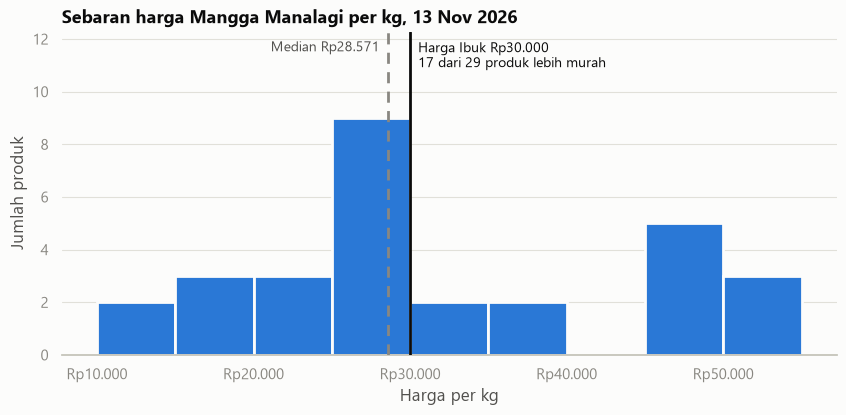

In [ ]:
batas = np.arange(10_000, hari_ini["harga_per_kg"].max() + 5_000, 5_000)
lebih_murah = (hari_ini["harga_per_kg"] < HARGA_IBUK).sum()

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.hist(hari_ini["harga_per_kg"], bins=batas, color=BIRU, edgecolor=PERMUKAAN, linewidth=2)
median = hari_ini["harga_per_kg"].median()
ax.set_ylim(0, ax.get_ylim()[1] * 1.3)   # ruang kosong di atas batang untuk label
atas = ax.get_ylim()[1]
# Each label goes on the side facing away from the other line, so they don't overlap when the lines are close.
ibuk_kanan = HARGA_IBUK >= median
ax.axvline(median, color=REDUP, linewidth=2, linestyle=(0, (4, 3)), zorder=3)
ax.text(median, atas * 0.97, f"Median {rupiah(median)}  " if ibuk_kanan else f"  Median {rupiah(median)}",
        ha="right" if ibuk_kanan else "left", va="top", fontsize=10, color=TINTA_2)
ax.axvline(HARGA_IBUK, color=TINTA, linewidth=2, zorder=3)
label_ibuk = f"  Harga Ibuk {rupiah(HARGA_IBUK)}\n  {lebih_murah} dari {len(hari_ini)} produk lebih murah"
ax.text(HARGA_IBUK, atas * 0.97, label_ibuk, ha="left" if ibuk_kanan else "right", va="top",
        fontsize=10, color=TINTA)
ax.xaxis.set_major_formatter(RUPIAH)
ax.yaxis.set_major_locator(mtick.MaxNLocator(integer=True))
ax.set(xlabel="Harga per kg", ylabel="Jumlah produk")
ax.set_title(f"Sebaran harga Mangga Manalagi per kg, {terakhir:%d %b %Y}")
ax.grid(axis="x", visible=False)
sns.despine(left=True)
plt.show()

## 3. Tren harian, produk yang sama

Kalau median dihitung dari *semua* produk, angkanya bisa bergeser hanya karena produk yang
muncul hari itu berbeda (20–31 produk per hari). Contoh: 11 Nov Blibli hilang (tarikan gagal),
dan produk Blibli rata-rata lebih murah, jadi median hari itu naik padahal harganya tidak berubah.

Jadi garis utama membandingkan setiap **produk tetap** (muncul minimal ⅔ dari jumlah hari)
dengan harga normalnya sendiri: `rasio = harga hari itu / median harga produk itu`. Median
rasio per hari × median harga normal = harga "produk yang sama". Produk yang absen satu hari
tidak menggeser garis. Sumbu y mulai dari Rp0 supaya perubahan kecil tidak tampak seperti lonjakan.

Produk tetap: 27 dari 39 (muncul ≥ 4 dari 6 hari)
             sama  semua
tanggal                 
2026-11-08  28571  29000
2026-11-09  28571  30750
2026-11-10  28571  29000
2026-11-11  28571  30750
2026-11-12  28571  29500
2026-11-13  28571  28571


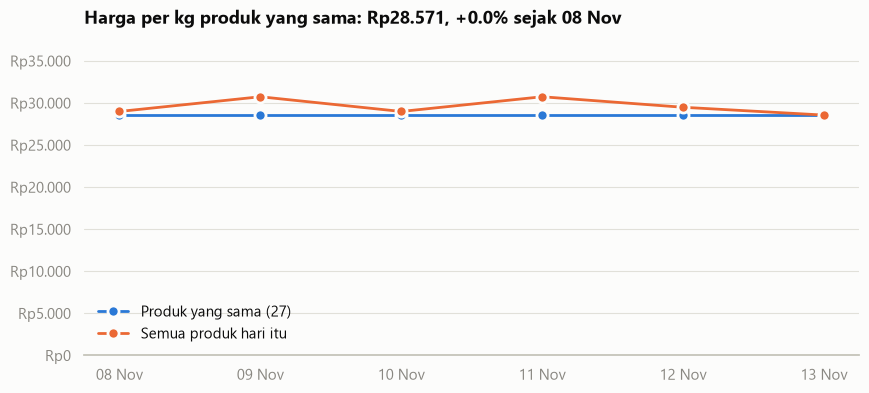

In [ ]:
jumlah_hari = df["tanggal"].nunique()
min_hari = int(np.ceil(jumlah_hari * 2 / 3))
hari_per_produk = df.groupby("produk_key")["tanggal"].nunique()
tetap = df[df["produk_key"].isin(hari_per_produk[hari_per_produk >= min_hari].index)].copy()
print(f"Produk tetap: {tetap['produk_key'].nunique()} dari {df['produk_key'].nunique()} (muncul ≥ {min_hari} dari {jumlah_hari} hari)")

normal = tetap.groupby("produk_key")["harga_per_kg"].median()
tetap["rasio"] = tetap["harga_per_kg"] / tetap["produk_key"].map(normal)
tren = pd.DataFrame({
    "sama": tetap.groupby("tanggal")["rasio"].median() * normal.median(),
    "semua": df.groupby("tanggal")["harga_per_kg"].median(),
})
print(tren.round(0).astype(int).to_string())

fig, ax = plt.subplots(figsize=(10, 4.2))
for kolom, warna, label in [("sama", BIRU, f"Produk yang sama ({len(normal)})"),
                            ("semua", ORANYE, "Semua produk hari itu")]:
    ax.plot(tren.index, tren[kolom], color=warna, marker="o", markersize=8,
            markeredgecolor=PERMUKAAN, markeredgewidth=2, label=label)
awal, akhir = tren["sama"].iloc[0], tren["sama"].iloc[-1]
ax.set_title(f"Harga per kg produk yang sama: {rupiah(akhir)}, {(akhir - awal) / awal:+.1%} sejak {tren.index[0]:%d %b}")
ax.set_ylim(0, tren.max().max() * 1.25)
ax.yaxis.set_major_formatter(RUPIAH)
ax.set_xticks(tren.index)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax.legend(loc="lower left", frameon=False)
ax.grid(axis="x", visible=False)
sns.despine(left=True)
plt.show()

## 5. Blibli vs Tokopedia, dan per wilayah

Ditampilkan sekarang supaya bentuknya terlihat, tetapi **jumlah produknya masih kecil**
(Blibli ±5 produk per hari). Angka `n` di setiap batang menunjukkan berapa produk di belakangnya;
jangan ambil kesimpulan dari kelompok dengan n < 10. Grafik ini baru layak setelah ±1 bulan data.

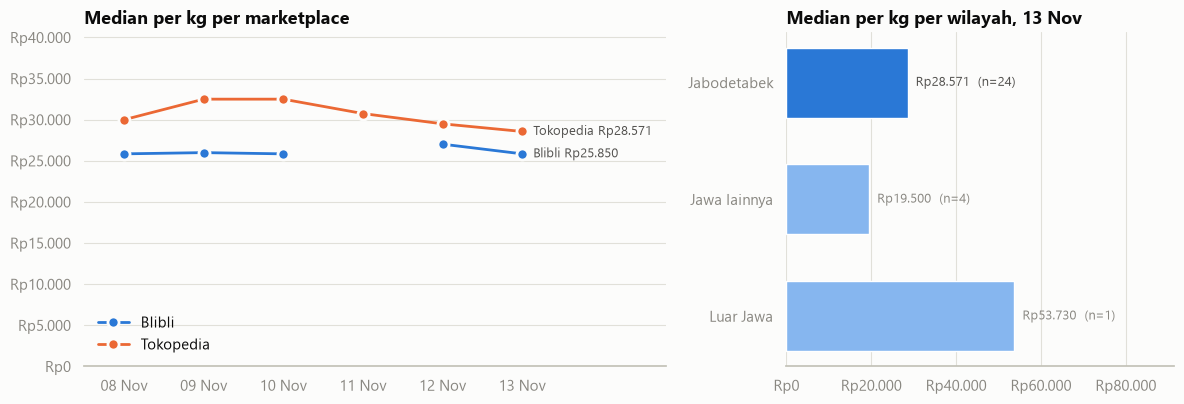

In [ ]:
fig, (kiri, kanan) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [3, 2]})

pasar = df.groupby(["tanggal", "sumber"])["harga_per_kg"].median().unstack()  # NaN = hari hilang → garis putus
for sumber, warna in [("blibli", BIRU), ("tokopedia", ORANYE)]:
    s = pasar[sumber]
    kiri.plot(s.index, s.values, color=warna, marker="o", markersize=8,
              markeredgecolor=PERMUKAAN, markeredgewidth=2, label=sumber.capitalize())
    kiri.annotate(f"{sumber.capitalize()} {rupiah(s.iloc[-1])}", (s.index[-1], s.iloc[-1]),
                  xytext=(8, 0), textcoords="offset points", va="center", fontsize=9.5, color=TINTA_2)
kiri.set_ylim(0, pasar.max().max() * 1.25)
kiri.set_xlim(pasar.index[0] - pd.Timedelta(hours=12), pasar.index[-1] + pd.Timedelta(days=1.8))
kiri.set_xticks(pasar.index)
kiri.yaxis.set_major_formatter(RUPIAH)
kiri.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
kiri.set_title("Median per kg per marketplace")
kiri.legend(loc="lower left", frameon=False)
kiri.grid(axis="x", visible=False)

wilayah = (hari_ini.groupby("region")["harga_per_kg"].agg(["median", "size"])
           .reindex(["jabodetabek", "jawa_lain", "luar_jawa"]).dropna())
nama = {"jabodetabek": "Jabodetabek", "jawa_lain": "Jawa lainnya", "luar_jawa": "Luar Jawa"}
# n < 10 dipudarkan (biru langkah 250): bentuknya terlihat, tetapi tidak menarik mata.
kanan.barh([nama[w] for w in wilayah.index], wilayah["median"], height=0.6,
           color=[BIRU if n >= 10 else "#86b6ef" for n in wilayah["size"]])
for i, (m, n) in enumerate(zip(wilayah["median"], wilayah["size"])):
    kanan.text(m, i, f"  {rupiah(m)}  (n={n:.0f})", va="center", fontsize=9.5,
               color=TINTA_2 if n >= 10 else REDUP)
kanan.invert_yaxis()
kanan.set_xlim(0, wilayah["median"].max() * 1.7)
kanan.xaxis.set_major_formatter(RUPIAH)
kanan.set_title(f"Median per kg per wilayah, {terakhir:%d %b}")
kanan.grid(axis="y", visible=False)
sns.despine(left=True)
plt.tight_layout()
plt.show()

## 6. Peringatan lonjakan harga

Setiap produk dibandingkan dengan **harganya sendiri** selama `JENDELA_HARI` hari kalender
sebelumnya (hari ini tidak ikut):

`rasio = harga hari ini / median harga produk itu dalam jendela`

- **Lonjakan toko**: rasio menyimpang ≥ `AMBANG_TOKO` (10%) **dan** harganya berbeda dari
  pengamatan sebelumnya. Jadi satu perubahan ditandai sekali, pada hari terjadinya, bukan
  berhari-hari sampai median jendela menyusul.
- **Lonjakan pasar**: *median* rasio semua produk hari itu menyimpang ≥ `AMBANG_PASAR` (5%).
  Median, jadi baru menyala kalau **lebih dari separuh** produk bergerak ke arah yang sama;
  satu toko tidak cukup.
- Produk butuh minimal `MIN_DATA` hari di jendelanya sebelum boleh dinilai.

Kenapa bukan aturan Hampel standar (3 × MAD)? Harga Manalagi jarang berubah, jadi MAD sering 0
dan setiap perubahan sekecil apa pun akan ditandai. Ambang persen lebih cocok.

Jendela memakai hari **kalender**, jadi hari yang hilang (misalnya Blibli 11 Nov) tidak
menggeser hitungan. Angka 7 hari, 10%, dan 5% adalah tebakan awal: setel ulang setelah
±1 bulan data.

           median_rasio  dinilai  naik  turun  lonjakan_pasar
tanggal                                                      
2026-11-11        +0.0%       10     0      0           False
2026-11-12        +0.0%       18     0      0           False
2026-11-13        +0.0%       26     0      1           False


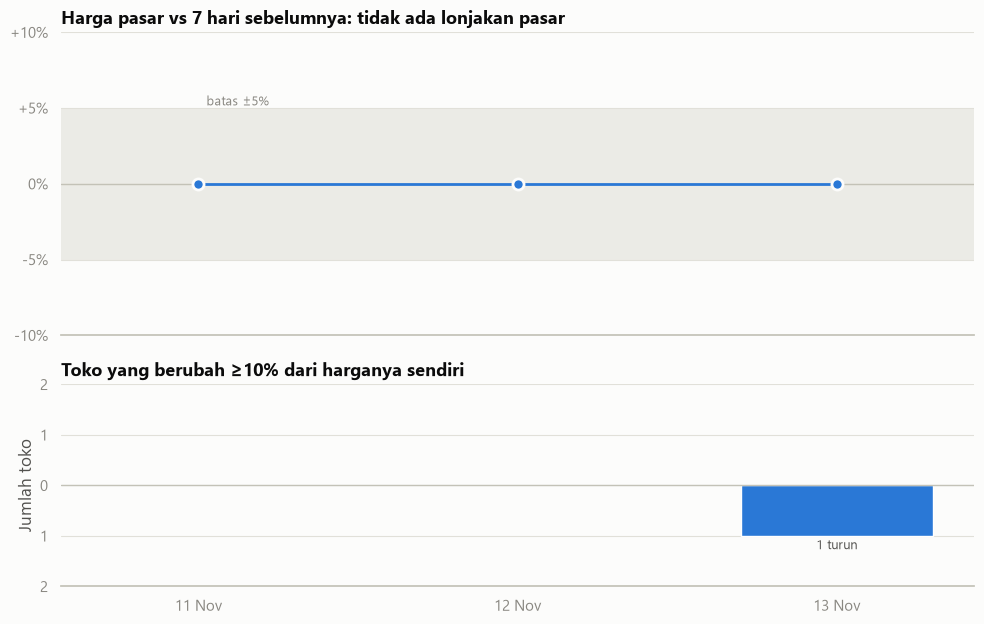


Lonjakan toko, 7 hari terakhir: 1


,tanggal,nama_toko,sumber,kota,sebelumnya,sekarang,perubahan
0,13 Nov,rumindonesia,tokopedia,Jakarta Selatan,Rp32.500,Rp25.000,-23.1%


In [ ]:
JENDELA_HARI = 7      # panjang jendela pembanding (hari kalender)
AMBANG_TOKO = 0.10    # lonjakan satu produk
AMBANG_PASAR = 0.05   # lonjakan median semua produk
MIN_DATA = 3          # minimal hari berdata dalam jendela

MERAH = "#e34948"     # naik (pasangan divergen biru-merah)

def median_jendela(g):
    s = g.set_index("tanggal")["harga_per_kg"]
    r = s.rolling(f"{JENDELA_HARI}D", closed="left")
    return pd.DataFrame({"tanggal": s.index, "median_jendela": r.median().values, "jumlah": r.count().values})

urut = df.sort_values(["produk_key", "tanggal"]).copy()
urut["harga_sebelumnya"] = urut.groupby("produk_key")["harga_per_kg"].shift()
banding = (urut.groupby("produk_key", group_keys=True)[["tanggal", "harga_per_kg"]]
           .apply(median_jendela).reset_index(level=0).reset_index(drop=True))
lonjak = urut.merge(banding, on=["produk_key", "tanggal"])
lonjak = lonjak[lonjak["jumlah"] >= MIN_DATA].copy()
lonjak["rasio"] = lonjak["harga_per_kg"] / lonjak["median_jendela"]
lonjak["lonjak_toko"] = ((lonjak["rasio"] - 1).abs() >= AMBANG_TOKO) & (lonjak["harga_per_kg"] != lonjak["harga_sebelumnya"])
lonjak["arah"] = np.sign(lonjak["rasio"] - 1).where(lonjak["lonjak_toko"], 0)

pasar = lonjak.groupby("tanggal").agg(
    median_rasio=("rasio", "median"),
    dinilai=("rasio", "size"),
    naik=("arah", lambda a: (a > 0).sum()),
    turun=("arah", lambda a: (a < 0).sum()),
)
pasar["lonjakan_pasar"] = (pasar["median_rasio"] - 1).abs() >= AMBANG_PASAR
print(pasar.assign(median_rasio=lambda d: (d["median_rasio"] - 1).map("{:+.1%}".format)).to_string())

fig, (atas, bawah) = plt.subplots(2, 1, figsize=(10, 6.4), sharex=True, gridspec_kw={"height_ratios": [3, 2]})

# Atas: perubahan median pasar terhadap jendela, dengan pita ambang.
ubah = (pasar["median_rasio"] - 1) * 100
batas_y = max(AMBANG_PASAR * 100 * 2, ubah.abs().max() * 1.3)
atas.axhspan(-AMBANG_PASAR * 100, AMBANG_PASAR * 100, color=GRID, alpha=0.6, linewidth=0)
atas.axhline(0, color=SUMBU, linewidth=1)
atas.plot(ubah.index, ubah.values, color=BIRU, marker="o", markersize=8,
          markeredgecolor=PERMUKAAN, markeredgewidth=2)
for t, v in ubah[pasar["lonjakan_pasar"]].items():
    atas.annotate(f"Lonjakan pasar {v:+.1f}%", (t, v), xytext=(0, 10), textcoords="offset points",
                  ha="center", fontsize=9.5, color=TINTA, weight="bold")
atas.text(ubah.index[0], AMBANG_PASAR * 100, f"  batas ±{AMBANG_PASAR:.0%}", va="bottom", fontsize=9, color=REDUP)
atas.set_ylim(-batas_y, batas_y)
atas.yaxis.set_major_locator(mtick.MaxNLocator(nbins=4, steps=[1, 2, 5, 10], symmetric=True))
atas.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:+.0f}%" if v else "0%"))
jumlah_lonjak = int(pasar["lonjakan_pasar"].sum())
atas.set_title(f"Harga pasar vs {JENDELA_HARI} hari sebelumnya: "
               + ("tidak ada lonjakan pasar" if jumlah_lonjak == 0 else f"{jumlah_lonjak} hari lonjakan pasar"))
atas.grid(axis="x", visible=False)

# Bawah: berapa toko naik (atas nol) dan turun (bawah nol) >= AMBANG_TOKO.
atas_batang = bawah.bar(pasar.index, pasar["naik"], color=MERAH, width=0.6)
bawah_batang = bawah.bar(pasar.index, -pasar["turun"], color=BIRU, width=0.6)
for t, n, k in zip(pasar.index, pasar["naik"], pasar["turun"]):
    if n:
        bawah.annotate(f"{n} naik", (t, n), xytext=(0, 3), textcoords="offset points",
                       ha="center", va="bottom", fontsize=9, color=TINTA_2)
    if k:
        bawah.annotate(f"{k} turun", (t, -k), xytext=(0, -3), textcoords="offset points",
                       ha="center", va="top", fontsize=9, color=TINTA_2)
batas_b = max(2, pasar[["naik", "turun"]].max().max() * 1.6)
bawah.set_ylim(-batas_b, batas_b)
bawah.axhline(0, color=SUMBU, linewidth=1)
bawah.yaxis.set_major_locator(mtick.MaxNLocator(integer=True))
bawah.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{abs(v):.0f}"))
bawah.set_ylabel("Jumlah toko")
bawah.set_title(f"Toko yang berubah ≥{AMBANG_TOKO:.0%} dari harganya sendiri")
bawah.set_xticks(pasar.index)
bawah.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
bawah.grid(axis="x", visible=False)
sns.despine(left=True)
plt.tight_layout()
plt.show()

terbaru = pasar.index.max()
daftar = lonjak[lonjak["lonjak_toko"]
                & (lonjak["tanggal"] > terbaru - pd.Timedelta(days=JENDELA_HARI))]
print(f"\nLonjakan toko, {JENDELA_HARI} hari terakhir: {len(daftar)}")
(daftar.assign(tanggal=daftar["tanggal"].dt.strftime("%d %b"),
               sebelumnya=daftar["median_jendela"].map(rupiah),
               sekarang=daftar["harga_per_kg"].map(rupiah),
               perubahan=(daftar["rasio"] - 1).map("{:+.1%}".format))
 [["tanggal", "nama_toko", "sumber", "kota", "sebelumnya", "sekarang", "perubahan"]]
 .sort_values("tanggal", ascending=False).reset_index(drop=True))